# 신약 후보물질 독성 예측 — 팀 공유 노트북

같이 보는 문서: `독성예측_팀공유_요약.md`

[이 노트북의 목적]
- 요약 문서에 적힌 **수치를 직접 재현**해서, 팀원 각자가 결과를 믿고 쓸 수 있게 함
- 파생변수를 만드는 함수(`build_derived_features`)를 제공 → `predict_input.csv`에도 그대로 적용 가능

[실행 방법]
- 같은 폴더에 `train.csv`를 두고 위에서부터 순서대로 실행 (전체 약 5분)
- 필요한 패키지: `pip install rdkit lightgbm`
- RDKit이 없으면 섹션 5~6은 자동으로 건너뜀

[⚠️ 가장 중요한 주의사항]
- **`label = 1` → 독성 없음 (Positive)**, **`label = 0` → 독성 있음 (Negative)**
- 평가지표 F1은 **label = 1(독성 없음)** 기준. 일반적인 관행(관심 대상 = 1)과 반대이므로 모든 그래프와 코드에서 방향을 확인할 것

## 1. 준비

- `N_JOBS`: 사용할 CPU 코어 수. 노트북이 느리거나 발열이 심하면 숫자를 줄이세요

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
import lightgbm as lgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

SEED = 42
TARGET = "label"
N_JOBS = 6                    # CPU 코어 수 (발열이 심하면 줄이기)
DESC_COLS = ["MolWt", "clogp", "sa_score", "qed"]
FP_BLOCKS = ["ecfp", "fcfp", "ptfp"]
LABEL_NAMES = {0: "0: Toxic", 1: "1: Non-toxic"}
LABEL_ORDER = ["0: Toxic", "1: Non-toxic"]
PALETTE = {"0: Toxic": "#d62728", "1: Non-toxic": "#1f77b4"}

try:
    from rdkit import Chem, RDLogger
    from rdkit.Chem import Lipinski, rdMolDescriptors
    from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
    from rdkit.Chem.MolStandardize import rdMolStandardize
    RDLogger.DisableLog("rdApp.*")
    HAS_RDKIT = True
except ImportError:
    HAS_RDKIT = False

print("LightGBM", lgb.__version__, "| RDKit 사용 가능:", HAS_RDKIT)

LightGBM 4.7.0 | RDKit 사용 가능: True


In [2]:
df = pd.read_csv("train.csv")
FP_COLS = {b: [c for c in df.columns if c.startswith(b + "_")] for b in FP_BLOCKS}
ALL_FP = sum(FP_COLS.values(), [])
df[ALL_FP] = df[ALL_FP].astype("uint8")
df["label_name"] = df[TARGET].map(LABEL_NAMES)
y = df[TARGET].values
n = len(df)
print("Data shape:", df.shape)

Data shape: (8349, 3079)


## 2. 라벨 분포와 넘어야 할 기준선

[Question] 독성 있음(0)과 없음(1)의 비율은? 모두 1로 예측하면 F1은 얼마인가?

**모두 1로 예측했을 때의 F1이 모델이 넘어야 할 최소 기준선**입니다. 이 값보다 낮으면 모델을 만든 의미가 없습니다.

,의미,건수,비율(%)
label,,,
0,독성 있음 (Negative),3807,45.598
1,독성 없음 (Positive),4542,54.402


모두 1로 예측했을 때 F1 = 0.705   ← 모델이 넘어야 할 기준선
(공식: 2p / (1 + p), p = label 1의 비율 = 0.544)


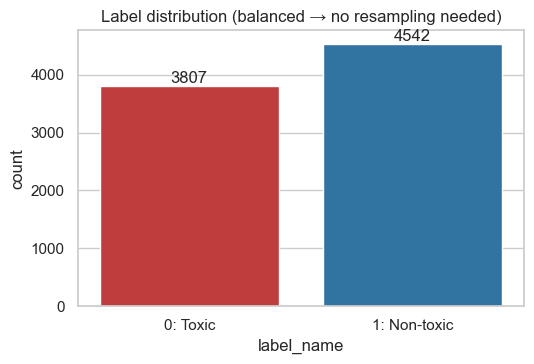

In [3]:
counts = df[TARGET].value_counts().sort_index()
trivial_f1 = f1_score(y, np.ones_like(y))
display(pd.DataFrame({
    "의미": ["독성 있음 (Negative)", "독성 없음 (Positive)"],
    "건수": counts.values,
    "비율(%)": (counts / n * 100).values,
}, index=counts.index.rename("label")))
print(f"모두 1로 예측했을 때 F1 = {trivial_f1:.3f}   ← 모델이 넘어야 할 기준선")
print(f"(공식: 2p / (1 + p), p = label 1의 비율 = {y.mean():.3f})")

plt.figure(figsize=(5.5, 3.8))
ax = sns.countplot(data=df, x="label_name", order=LABEL_ORDER, hue="label_name",
                   palette=PALETTE, legend=False)
for c in ax.containers:
    ax.bar_label(c)
plt.title(f"Label distribution (balanced → no resampling needed)")
plt.tight_layout()
plt.show()

## 3. 데이터 품질 — 중복과 라벨 충돌

[Question] 피처가 완전히 같은 행이 있는가? 그중 라벨이 반대인 경우는?

Fingerprint는 **카이랄성(입체 구조)을 담지 않습니다.** 그래서 `[C@H]`와 `[C@@H]`만 다른 거울상 이성질체는 피처 벡터가 완전히 같아집니다. 실제 독성이 다르면 **모델이 원리상 구분할 수 없는 오차**가 됩니다.

In [4]:
FEATURES = ALL_FP + DESC_COLS
feature_hash = pd.util.hash_pandas_object(df[FEATURES], index=False)
dup_mask = feature_hash.duplicated(keep=False)
group_label_n = df.loc[dup_mask, TARGET].groupby(feature_hash[dup_mask]).nunique()
conflict = group_label_n[group_label_n > 1].index

display(pd.Series({
    "결측값": int(df.isna().sum().sum()),
    "피처가 완전히 같은 행": int(dup_mask.sum()),
    "중복 그룹 수": len(group_label_n),
    "라벨이 충돌하는 그룹 수": len(conflict),
}).to_frame("건수"))

print("라벨 충돌 예시 (피처는 같은데 라벨이 반대):")
example = df.loc[feature_hash.isin(conflict[:2])].assign(group=feature_hash)
display(example[["SMILES", TARGET, "group"]].sort_values("group").head(4))

patterns = {
    "염·혼합물 ('.')": r"\.",
    "전하 표기": r"\[[^\]]*[+-]",
    "입체 표기 ('@')": r"@",
}
display(pd.DataFrame([
    {"패턴": k, "행 수": int(df["SMILES"].str.contains(v, regex=True).sum())}
    for k, v in patterns.items()]).set_index("패턴"))

,건수
결측값,0
피처가 완전히 같은 행,534
중복 그룹 수,241
라벨이 충돌하는 그룹 수,33


라벨 충돌 예시 (피처는 같은데 라벨이 반대):


,SMILES,label,group
4262,C[C@@H]1CCCN1CCCOc2ccc(cc2)N3CCN(CC3=O)C(=O)c4...,0,70787966358207030
4269,C[C@H]1CCCN1CCCOc2ccc(cc2)N3CCN(CC3=O)C(=O)c4c...,1,70787966358207030
6530,CC(C)c1cc(cc2nc(oc12)c3ccc(cc3)C(=O)NC[C@@H]4C...,0,656389606542746734
6531,CC(C)c1cc(cc2nc(oc12)c3ccc(cc3)C(=O)NC[C@@H]4C...,1,656389606542746734


,행 수
패턴,
염·혼합물 ('.'),262
전하 표기,151
입체 표기 ('@'),3689


## 4. 핵심 발견 ① — 지용성(clogp)이 높을수록 독성이 많다

[Question] 기술자 4개 중 독성과 관계가 강한 것은? 어떤 형태의 관계인가?

- **clogp**: 단조 관계. 높을수록 독성
- **MolWt**: 상관계수로는 안 보이지만 **U자형**. "상관이 낮으니 버린다"고 하면 안 되는 사례

,중앙값 (독성),중앙값 (비독성),단독 AUC
변수,,,
MolWt,440.996,441.748,0.495
clogp,4.152,3.368,0.337
sa_score,3.032,3.143,0.541
qed,0.538,0.571,0.548


AUC가 0.5에서 멀수록 강한 신호. 0.5 미만 = 값이 클수록 독성


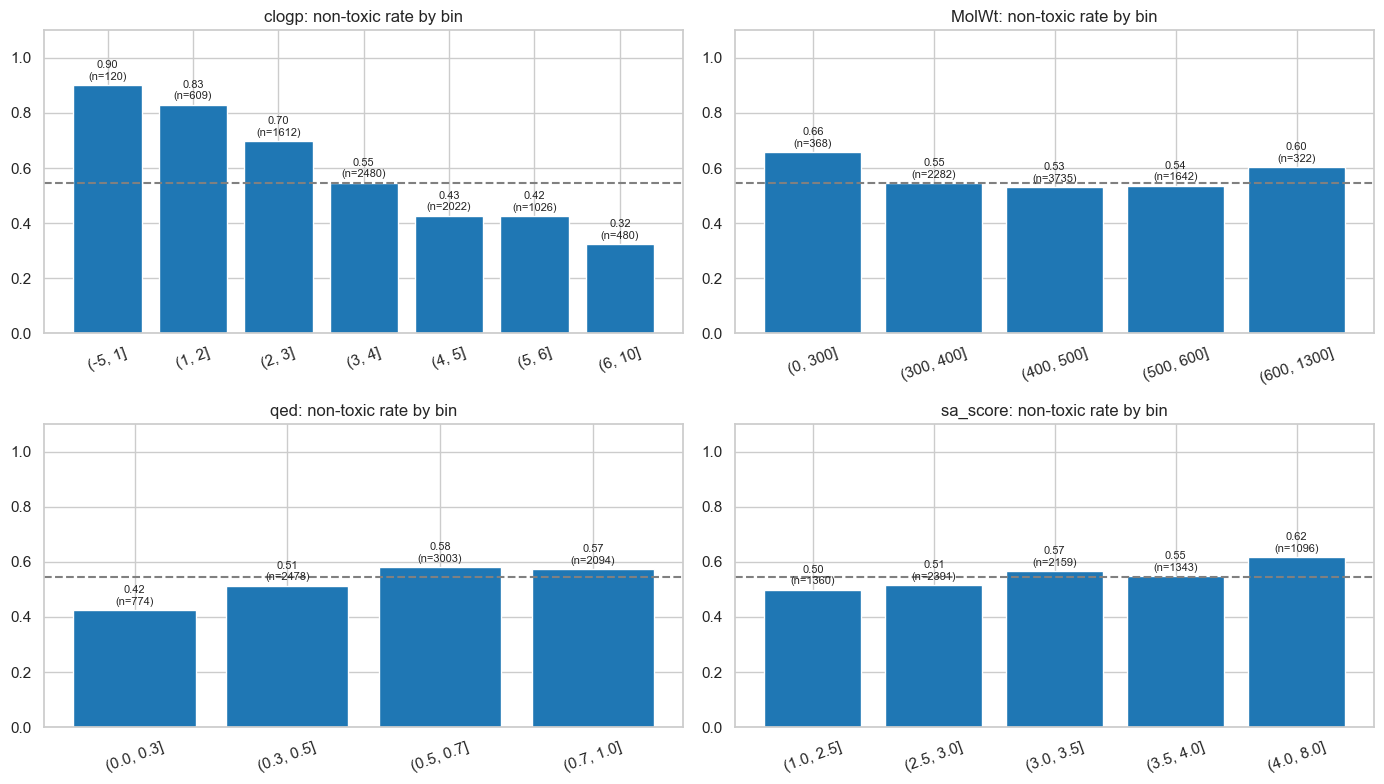

In [5]:
rows = []
for col in DESC_COLS:
    toxic, nontoxic = df.loc[y == 0, col], df.loc[y == 1, col]
    rows.append({"변수": col, "중앙값 (독성)": toxic.median(), "중앙값 (비독성)": nontoxic.median(),
                 "단독 AUC": roc_auc_score(y, df[col])})
display(pd.DataFrame(rows).set_index("변수"))
print("AUC가 0.5에서 멀수록 강한 신호. 0.5 미만 = 값이 클수록 독성")

BINS = {"clogp": [-5, 1, 2, 3, 4, 5, 6, 10], "MolWt": [0, 300, 400, 500, 600, 1300],
        "qed": [0, 0.3, 0.5, 0.7, 1.0], "sa_score": [1, 2.5, 3.0, 3.5, 4.0, 8.0]}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (col, bins) in zip(axes.flatten(), BINS.items()):
    g = df.groupby(pd.cut(df[col], bins), observed=True)[TARGET]
    rate, size = g.mean(), g.size()
    ax.bar(rate.index.astype(str), rate.values, color="#1f77b4")
    ax.axhline(y.mean(), color="gray", linestyle="--")
    for i, (r, s) in enumerate(zip(rate.values, size.values)):
        ax.text(i, r + 0.02, f"{r:.2f}\n(n={s})", ha="center", fontsize=8)
    ax.set_ylim(0, 1.1)
    ax.set_title(f"{col}: non-toxic rate by bin")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 5. 핵심 발견 ② — 가장 강한 신호는 "지용성 + 염기성 아민" (CAD 규칙)

[Question] 도메인 지식을 SMARTS로 옮기면 독성 분리가 더 선명해지는가?

**SMARTS**는 분자에서 특정 부분 구조를 찾는 검색 언어입니다. SMILES가 "이 분자는 무엇인가"라면, SMARTS는 "이런 구조를 가진 분자를 찾아라"는 질의입니다.

여기서 만드는 **CAD 규칙**(Cationic Amphiphilic Drug) = `clogp > 3` **그리고** `염기성 아민 보유`
- 지용성이 높으면서 염기성 질소를 가진 분자는 hERG 심장독성·인지질증 위험이 크다고 알려져 있습니다
- EDA에서 ECFP 상위 비트를 역추적했을 때도 독성 쪽은 **3차 아민**, 비독성 쪽은 **카르보닐·카복실**이 나왔습니다

아래 `build_derived_features()`는 **`predict_input.csv`에도 그대로 적용**할 수 있습니다.

In [6]:
derived = None
if HAS_RDKIT:
    SMARTS_PATTERNS = {
        # 독성 경고 구조 (toxicophore)
        "nitro": "[$([NX3](=O)=O),$([NX3+](=O)[O-])]",          # 니트로기: 변이원성
        "aromatic_amine": "c[NX3;H2,H1;!$(NC=[O,S,N])]",        # 방향족 아민: 대사 활성화
        "michael_acceptor": "[CX3]=[CX3][CX3]=[OX1]",           # 단백질과 공유결합
        # 독성 쪽 신호 (염기성 질소)
        "basic_amine": "[NX3;+0;!$(N~[!#1;!$([CX4])])]",         # 지방족 아민
        "tertiary_amine": "[NX3;H0;+0]([CX4])([CX4])[CX4]",      # 3차 아민
        # 비독성 쪽 신호 (산성·극성 작용기)
        "carboxylic_acid": "[CX3](=O)[OX2H1,OX1-]",
        "carbonyl": "[CX3]=[OX1]",
        "amide": "[CX3](=O)[NX3]",
        "sulfonamide": "S(=O)(=O)[NX3]",
        "phenol": "c[OX2H]",
        "aryl_halide": "c[F,Cl,Br,I]",
    }
    patterns = {k: Chem.MolFromSmarts(v) for k, v in SMARTS_PATTERNS.items()}
    assert all(p is not None for p in patterns.values()), "잘못된 SMARTS가 있습니다"

    def make_catalog(catalog):
        params = FilterCatalogParams()
        params.AddCatalog(catalog)
        return FilterCatalog(params)

    brenk = make_catalog(FilterCatalogParams.FilterCatalogs.BRENK)   # RDKit 내장 구조 경고
    largest_fragment = rdMolStandardize.LargestFragmentChooser()

    def mol_features(smiles):
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return {}
        mol = largest_fragment.choose(mol)        # 염·용매 조각 제거 후 계산
        feats = {f"smarts_{k}": len(mol.GetSubstructMatches(p)) for k, p in patterns.items()}
        feats.update({
            "brenk_alerts": len(brenk.GetMatches(mol)),
            "TPSA": rdMolDescriptors.CalcTPSA(mol),          # 극성 표면적
            "HBD": Lipinski.NumHDonors(mol),
            "HBA": Lipinski.NumHAcceptors(mol),
            "RotB": rdMolDescriptors.CalcNumRotatableBonds(mol),
            "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
            "Fsp3": rdMolDescriptors.CalcFractionCSP3(mol),  # sp3 탄소 비율 (입체적 복잡도)
        })
        return feats

    def build_derived_features(data):
        """SMILES·clogp·MolWt 컬럼이 있는 DataFrame → 파생변수 (train·predict 공용)"""
        f = pd.DataFrame([mol_features(s) for s in data["SMILES"]], index=data.index)
        f["rule_cad"] = ((data["clogp"] > 3) & (f["smarts_basic_amine"] > 0)).astype(int)
        f["rule_pfizer_3_75"] = ((data["clogp"] > 3) & (f["TPSA"] < 75)).astype(int)
        f["rule_lipinski_viol"] = ((data["MolWt"] > 500).astype(int) + (data["clogp"] > 5)
                                   + (f["HBD"] > 5) + (f["HBA"] > 10))
        return f

    t = time.time()
    derived = build_derived_features(df)
    derived = derived[[c for c in derived.columns if derived[c].nunique() > 1]]
    print(f"파생변수 {derived.shape[1]}개 생성 ({time.time() - t:.0f}초)")
else:
    print("RDKit 미설치 → 섹션 5~6을 건너뜁니다. (pip install rdkit)")

파생변수 21개 생성 (4초)


,해당 비율(%),비독성 비율 (해당),비독성 비율 (미해당),차이
피처,,,,
rule_cad,47.143,0.376,0.694,-0.318
rule_pfizer_3_75,40.196,0.377,0.656,-0.279
smarts_basic_amine,67.014,0.475,0.685,-0.211
smarts_tertiary_amine,48.042,0.455,0.627,-0.172
smarts_carboxylic_acid,4.492,0.813,0.531,0.282
smarts_carbonyl,63.517,0.602,0.442,0.160
brenk_alerts,24.039,0.487,0.562,-0.075
(비교) clogp > 3 단독,71.961,0.467,0.742,-0.275


전체 비독성 비율 = 0.544
→ CAD 규칙이 clogp > 3 단독보다 분리가 선명함 (차이의 절댓값이 더 큼)


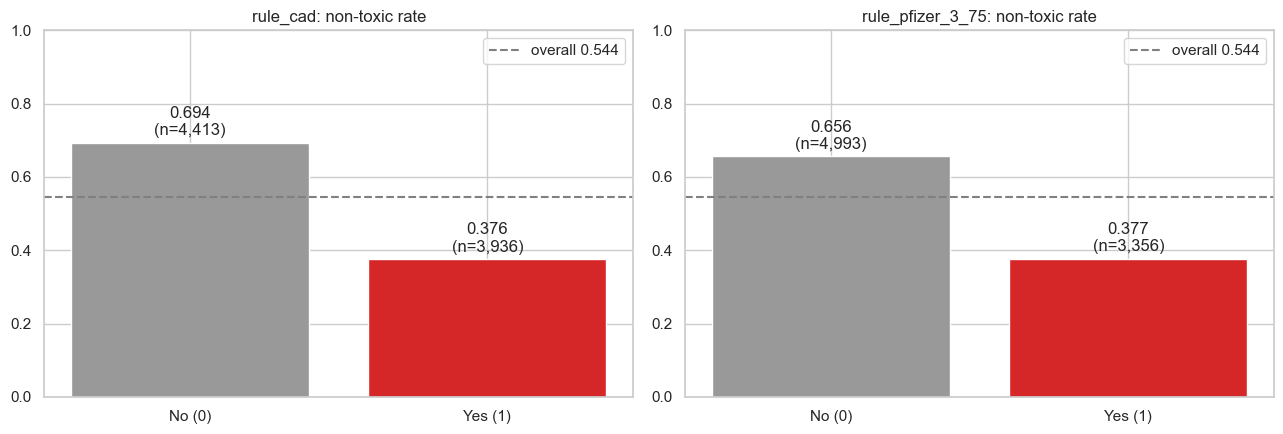

In [7]:
if derived is not None:
    rows = []
    for col in ["rule_cad", "rule_pfizer_3_75", "smarts_basic_amine", "smarts_tertiary_amine",
                "smarts_carboxylic_acid", "smarts_carbonyl", "brenk_alerts"]:
        present = (derived[col] > 0).values
        rows.append({"피처": col, "해당 비율(%)": present.mean() * 100,
                     "비독성 비율 (해당)": y[present].mean(),
                     "비독성 비율 (미해당)": y[~present].mean()})
    # 비교용: clogp > 3 단독 규칙
    c3 = (df["clogp"] > 3).values
    rows.append({"피처": "(비교) clogp > 3 단독", "해당 비율(%)": c3.mean() * 100,
                 "비독성 비율 (해당)": y[c3].mean(), "비독성 비율 (미해당)": y[~c3].mean()})
    table = pd.DataFrame(rows).set_index("피처")
    table["차이"] = table["비독성 비율 (해당)"] - table["비독성 비율 (미해당)"]
    display(table)
    print(f"전체 비독성 비율 = {y.mean():.3f}")
    print("→ CAD 규칙이 clogp > 3 단독보다 분리가 선명함 (차이의 절댓값이 더 큼)")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, col in zip(axes, ["rule_cad", "rule_pfizer_3_75"]):
        g = pd.Series(y).groupby(derived[col].values).agg(["mean", "size"])
        ax.bar(["No (0)", "Yes (1)"], g["mean"], color=["#999999", "#d62728"])
        for i, (r, s) in enumerate(zip(g["mean"], g["size"])):
            ax.text(i, r + 0.02, f"{r:.3f}\n(n={s:,})", ha="center")
        ax.axhline(y.mean(), color="gray", linestyle="--", label=f"overall {y.mean():.3f}")
        ax.set_ylim(0, 1.0)
        ax.set_title(f"{col}: non-toxic rate")
        ax.legend()
    plt.tight_layout()
    plt.show()

## 6. 핵심 발견 ③ — 신호는 기술자가 아니라 구조에 있다

[Question] Fingerprint 블록 하나만 써도 기술자 4개보다 나은가?

⚠️ 여기의 F1은 **무작위 분할** 결과입니다. 섹션 7에서 보듯 이 점수는 낙관적입니다.

기술자 4개만        F1 = 0.703 ± 0.013   (3초)


ECFP만          F1 = 0.796 ± 0.010   (6초)


FCFP만          F1 = 0.799 ± 0.009   (5초)


PTFP만          F1 = 0.792 ± 0.009   (6초)


전체 피처          F1 = 0.816 ± 0.012   (7초)


,컬럼 수,F1 (무작위 5-fold),std
피처 세트,,,
기술자 4개만,4,0.703,0.013
ECFP만,1024,0.796,0.010
FCFP만,1024,0.799,0.009
PTFP만,1024,0.792,0.009
전체 피처,3076,0.816,0.012
기준선: 모두 1로 예측,0,0.705,0.000


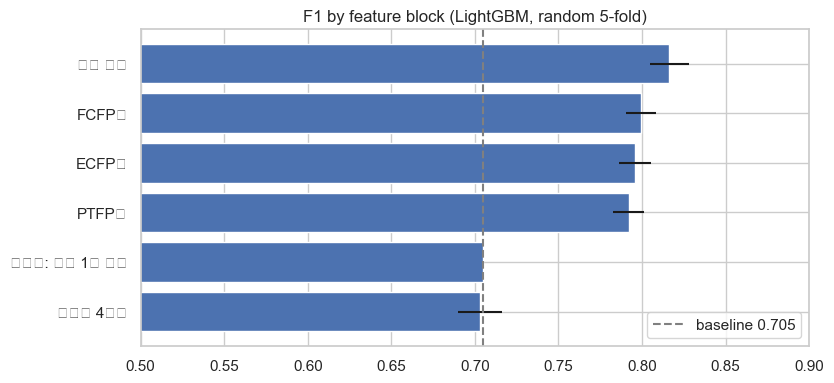

In [8]:
def lgbm():
    return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=SEED,
                              verbose=-1, n_jobs=N_JOBS)


def cv_f1(cols_or_X, cv, groups=None):
    X = cols_or_X if isinstance(cols_or_X, np.ndarray) else df[cols_or_X].values.astype(np.float32)
    scores = []
    for tr, va in cv.split(X, y, groups):
        p = lgbm().fit(X[tr], y[tr]).predict_proba(X[va])[:, 1]
        scores.append(f1_score(y[va], p >= 0.5))
    return float(np.mean(scores)), float(np.std(scores))


cv_random = StratifiedKFold(5, shuffle=True, random_state=SEED)
sets = {"기술자 4개만": DESC_COLS, "ECFP만": FP_COLS["ecfp"], "FCFP만": FP_COLS["fcfp"],
        "PTFP만": FP_COLS["ptfp"], "전체 피처": FEATURES}
rows = []
for name, cols in sets.items():
    t = time.time()
    m, s = cv_f1(cols, cv_random)
    rows.append({"피처 세트": name, "컬럼 수": len(cols), "F1 (무작위 5-fold)": m, "std": s})
    print(f"{name:14s} F1 = {m:.3f} ± {s:.3f}   ({time.time() - t:.0f}초)")
rows.append({"피처 세트": "기준선: 모두 1로 예측", "컬럼 수": 0, "F1 (무작위 5-fold)": trivial_f1, "std": 0.0})
block_results = pd.DataFrame(rows).set_index("피처 세트")
display(block_results)

plot = block_results["F1 (무작위 5-fold)"].sort_values()
plt.figure(figsize=(8.5, 4))
plt.barh(plot.index, plot.values, xerr=block_results.loc[plot.index, "std"], color="#4c72b0")
plt.axvline(trivial_f1, color="gray", linestyle="--", label=f"baseline {trivial_f1:.3f}")
plt.xlim(0.5, 0.9)
plt.title("F1 by feature block (LightGBM, random 5-fold)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. 핵심 발견 ④ — 무작위 분할은 점수를 부풀린다

[Question] 비슷한 구조가 train과 valid에 나뉘어 들어가면 점수가 얼마나 낙관적이 되는가?

화합물은 **유도체 군집**을 이룹니다. 최근접 이웃과의 Tanimoto 유사도 중앙값이 0.80입니다. 무작위로 나누면 거의 같은 분자가 양쪽에 들어가서, 모델이 "본 적 있는 것"을 맞히는 셈이 됩니다.

**Butina 클러스터링**으로 유사도 0.6 이상인 분자를 한 묶음으로 만들고, **같은 묶음은 반드시 같은 fold에** 넣어서 다시 평가합니다.

In [9]:
def tanimoto_matrix(a):
    a = a.astype(np.float32)
    inter = a @ a.T
    cnt = a.sum(1)
    return inter / np.maximum(cnt[:, None] + cnt[None, :] - inter, 1e-9)


def butina_clusters(sim, threshold=0.6):
    neighbours = sim >= threshold
    order = np.argsort(-neighbours.sum(axis=1), kind="stable")
    cluster = np.full(len(sim), -1)
    nid = 0
    for i in order:
        if cluster[i] != -1:
            continue
        members = np.where(neighbours[i] & (cluster == -1))[0]
        cluster[members] = nid
        cluster[i] = nid
        nid += 1
    return cluster


sim = tanimoto_matrix(df[FP_COLS["ecfp"]].values)
np.fill_diagonal(sim, -1)
nn_sim = sim.max(axis=1)
nn_same_label = y == y[sim.argmax(axis=1)]
print(f"최근접 이웃 Tanimoto 중앙값 = {np.median(nn_sim):.3f}")
print(f"최근접 이웃과 라벨이 같은 비율 = {nn_same_label.mean():.3f}")

cluster_ids = butina_clusters(sim, 0.6)
print(f"구조 클러스터 {cluster_ids.max() + 1:,}개")

X_all = df[FEATURES].values.astype(np.float32)
rows = []
for name, (cv, g) in {
    "무작위 5-fold": (StratifiedKFold(5, shuffle=True, random_state=SEED), None),
    "구조 클러스터 5-fold": (StratifiedGroupKFold(5, shuffle=True, random_state=SEED), cluster_ids),
}.items():
    t = time.time()
    m, s = cv_f1(X_all, cv, g)
    rows.append({"분할 방식": name, "F1": m, "std": s})
    print(f"{name:20s} F1 = {m:.3f} ± {s:.3f}   ({time.time() - t:.0f}초)")
split_results = pd.DataFrame(rows).set_index("분할 방식")
split_results["무작위 대비 차이"] = split_results["F1"] - split_results["F1"].iloc[0]
display(split_results)
print("→ 모델 비교·임계값 튜닝은 반드시 '구조 클러스터 분할' 점수 기준으로 할 것")

최근접 이웃 Tanimoto 중앙값 = 0.797
최근접 이웃과 라벨이 같은 비율 = 0.762
구조 클러스터 2,233개


무작위 5-fold           F1 = 0.816 ± 0.012   (7초)


구조 클러스터 5-fold       F1 = 0.757 ± 0.027   (7초)


,F1,std,무작위 대비 차이
분할 방식,,,
무작위 5-fold,0.816,0.012,0.000
구조 클러스터 5-fold,0.757,0.027,-0.059


→ 모델 비교·임계값 튜닝은 반드시 '구조 클러스터 분할' 점수 기준으로 할 것


## 8. 임계값 튜닝 — 가장 효율이 좋은 개선

[Question] 기본 임계값 0.5를 그대로 쓰면 되는가?

F1은 임계값에 민감합니다. **OOF 예측에서 F1이 최대가 되는 임계값**을 찾으면 모델을 바꾸지 않고도 점수가 오릅니다. 실제로 전체 성능 향상(+0.028) 중 **임계값 조정이 +0.018**을 차지했습니다.

⚠️ 다만 임계값을 낮추면 더 많은 분자를 "안전"으로 판정합니다. **Specificity(독성을 독성으로 잡아내는 비율)가 떨어진다**는 점을 함께 봐야 합니다.

,F1,Precision,Recall,Specificity (독성 탐지율),독성을 안전으로 오판 (FP)
임계값 0.5,0.757,0.727,0.790,0.645,1350.000
임계값 0.37 (F1 최대),0.769,0.686,0.875,0.523,1817.000


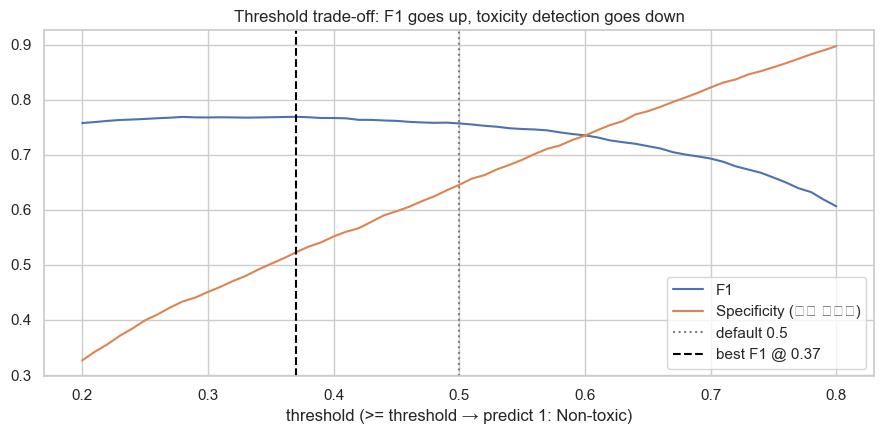

발표 포인트: 채점은 F1이지만, 업무상 가장 위험한 것은 독성 물질을 안전하다고 판정하는 것


In [10]:
cv_cluster = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
oof = np.zeros(n)
for tr, va in cv_cluster.split(X_all, y, cluster_ids):
    oof[va] = lgbm().fit(X_all[tr], y[tr]).predict_proba(X_all[va])[:, 1]

grid = np.arange(0.20, 0.80, 0.01)
f1s = np.array([f1_score(y, oof >= t) for t in grid])
best_t = float(grid[f1s.argmax()])


def metrics_at(t):
    pred = oof >= t
    tp = np.sum(pred & (y == 1)); fp = np.sum(pred & (y == 0))
    fn = np.sum(~pred & (y == 1)); tn = np.sum(~pred & (y == 0))
    return {"F1": 2 * tp / (2 * tp + fp + fn), "Precision": tp / max(tp + fp, 1),
            "Recall": tp / max(tp + fn, 1), "Specificity (독성 탐지율)": tn / max(tn + fp, 1),
            "독성을 안전으로 오판 (FP)": int(fp)}


display(pd.DataFrame({f"임계값 0.5": metrics_at(0.5),
                      f"임계값 {best_t:.2f} (F1 최대)": metrics_at(best_t)}).T)

spec = [metrics_at(t)["Specificity (독성 탐지율)"] for t in grid]
plt.figure(figsize=(9, 4.5))
plt.plot(grid, f1s, label="F1")
plt.plot(grid, spec, label="Specificity (독성 탐지율)")
plt.axvline(0.5, color="gray", linestyle=":", label="default 0.5")
plt.axvline(best_t, color="black", linestyle="--", label=f"best F1 @ {best_t:.2f}")
plt.xlabel("threshold (>= threshold → predict 1: Non-toxic)")
plt.title("Threshold trade-off: F1 goes up, toxicity detection goes down")
plt.legend()
plt.tight_layout()
plt.show()
print("발표 포인트: 채점은 F1이지만, 업무상 가장 위험한 것은 독성 물질을 안전하다고 판정하는 것")

## 9. 정리 — 팀이 합의한 모델링 방침

| 항목 | 결정 | 근거 |
|---|---|---|
| 라벨 방향 | `label = 1`이 독성 **없음**. `f1_score(..., pos_label=1)` | 강의안 p.11 |
| 검증 | **구조 클러스터 5-fold** + 홀드아웃 | 무작위 분할은 약 0.06 부풀림 (섹션 7) |
| 리샘플링 | 안 함 | 54:46으로 균형 (섹션 2) |
| 상수·중복 비트 | 제거 | 정보 없음, 성능 변화 없음 |
| 이상치·입체 중복 | 유지 | 실제 분자이고 신호가 있음 |
| PCA | 쓰지 않음 | F1 0.618로 기준선 미만 |
| 임계값 | OOF에서 F1 최대값 탐색 | 가장 효율이 좋은 개선 (섹션 8) |
| 파생변수 | CAD·Pfizer 3/75 등 도메인 규칙 중심 | 가장 강한 단일 신호 (섹션 5) |

**시도했지만 효과가 없던 것**: RDKit 기술자 217개 전체 추가(AUC 하락), MACCS, 입체 피처, Tanimoto SVM, 로지스틱 회귀

**남은 일**: `predict_input.csv` 수령 → train과의 유사도 분포 확인 → 모델 재실행 → 제출 파일 생성

자세한 내용과 현재 모델 성능(홀드아웃 F1 0.784)은 `독성예측_팀공유_요약.md`를 참고하세요.